In [1]:
# imports to enable the notebook to access the src folder
import sys
import os
import numpy as np
sys.path.append(os.path.dirname(os.getcwd()))

# import Antoine calculator
from src.pure import AntoineCalculator

# instantiate the calculator
antoine_calc = AntoineCalculator()

In [ ]:
# define compound
compound = {'CH3':3, 'CH':1, 'CH2COO':1}#{'H2O': 1}
#compound = {'H2O': 1}
#compound = {'DOH': 1}

# instantiate property calculator
from src.pure import PropertyCalculator
pure_calc = PropertyCalculator()

# calculate the required properties
critical_props = pure_calc.calculate(compound, properties=['tc', 'pc', 'tb', 'ac'])

# solve for the Antoine parameters
results = antoine_calc.calculate_antoine_parameters(compound, critical_properties=critical_props, method="acentric_factor")

Characteristic points (T [K], P [bar]): (373.1499999999999, 1.01325), (452.89999999999986, 9.972940978725989), (646.9999999999999, 220.6400000000002)


In [3]:
# print the anointe parameters
print(f"A: {results['A']}")
print(f"B: {results['B']}")
print(f"C: {results['C']}")
# print the range of T: tb to Tc
print(f"T range: {critical_props['tb']} K to {critical_props['tc']} K")

A: 5.276150790167597
B: 1810.313164589222
C: -29.66536409838349
T range: 373.1499999999999 K to 646.9999999999999 K


P_sat_calc min: 1.0132500000000007 bar
P_sat_calc max: 220.63999999999993 bar
P_sat_calc max should be: 220.6400000000002 bar


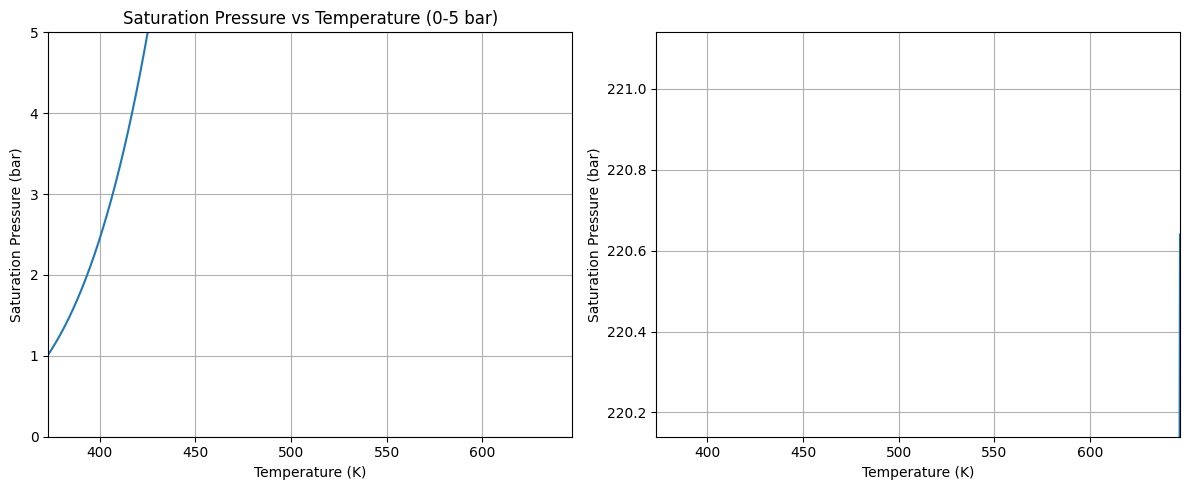

In [ ]:
# create T range
T_range = np.linspace(critical_props['tb'], critical_props['tc'], 1000)
# calculate Psat using the calculated Antoine parameters
P_sat_calc = antoine_calc.antoine_correlation(A=results['A'],
                                              B=results['B'],
                                              C=results['C'],
                                              T=T_range)
# print max and min of P_sat_calc
print(f"P_sat_calc min: {min(P_sat_calc)} bar")
print(f"P_sat_calc max: {max(P_sat_calc)} bar")
print(f"P_sat_calc max should be: {critical_props['pc']} bar")

# plot zoomed in version: where psat is minimum and maximum
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left subplot: zoomed to 0-5 bar
ax1.plot(T_range, P_sat_calc)
ax1.set_xlim(critical_props['tb'], critical_props['tc'])
ax1.set_ylim(0, 5)
ax1.set_xlabel('Temperature (K)')
ax1.set_ylabel('Saturation Pressure (bar)')
ax1.set_title('Saturation Pressure vs Temperature (0-5 bar)')
ax1.grid()

# Right subplot: zoomed around maximum
psat_max = np.max(P_sat_calc)
ax2.plot(T_range, P_sat_calc)
ax2.set_xlim(critical_props['tb'], critical_props['tc'])
ax2.set_ylim(critical_props['pc'] - 0.5, critical_props['pc'] + 0.5)  # adjust range as needed
ax2.set_xlabel('Temperature (K)')
ax2.set_ylabel('Saturation Pressure (bar)')
#ax2.set_title(f'Saturation Pressure vs Temperature (around max = {psat_max:.2f} bar)')
ax2.grid()

plt.tight_layout()
plt.show()